# Model Comparisons

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

sns.set_theme(style="whitegrid", palette="Set2")

## Loading Model Predictions

In [3]:
models = {
    "Logistic Regression": pd.read_csv("logistic_regression/predictions.csv"),
    "KNN": pd.read_csv("KNN/predictions.csv"),
    "MLP": pd.read_csv("MLP/predictions.csv"),
    "Random Forest": pd.read_csv("random_forest/predictions.csv"),
    "XGBoost": pd.read_csv("XGBoost/predictions.csv"),
}

## Compare Metrics

In [5]:
results = []

for name, df in models.items():
    actual = df["actual"]
    predicted = df["prediction"]
    probability = df["probability_non_benign"]

    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1 Score": f1_score(actual, predicted, zero_division=0),
        "Specificity": tn / (tn + fp),
        "FPR": fp / (fp + tn),
        "ROC-AUC": roc_auc_score(actual, probability),
        "PR-AUC": average_precision_score(actual, probability)
    })

results = pd.DataFrame(results).set_index("Model")
display(results.round(4))

,Accuracy,Precision,Recall,F1 Score,Specificity,FPR,ROC-AUC,PR-AUC
Model,,,,,,,,
Logistic Regression,0.9802,0.0700,0.8873,0.1298,0.9803,0.0197,0.9622,0.7055
KNN,0.9980,0.4372,0.7606,0.5553,0.9984,0.0016,0.8868,0.5576
MLP,0.9994,0.8450,0.7676,0.8044,0.9998,0.0002,0.9503,0.8066
Random Forest,0.9995,0.8880,0.7817,0.8315,0.9998,0.0002,0.9534,0.8217
XGBoost,0.9993,0.7917,0.8028,0.7972,0.9996,0.0004,0.9673,0.8137


## Compare Performance

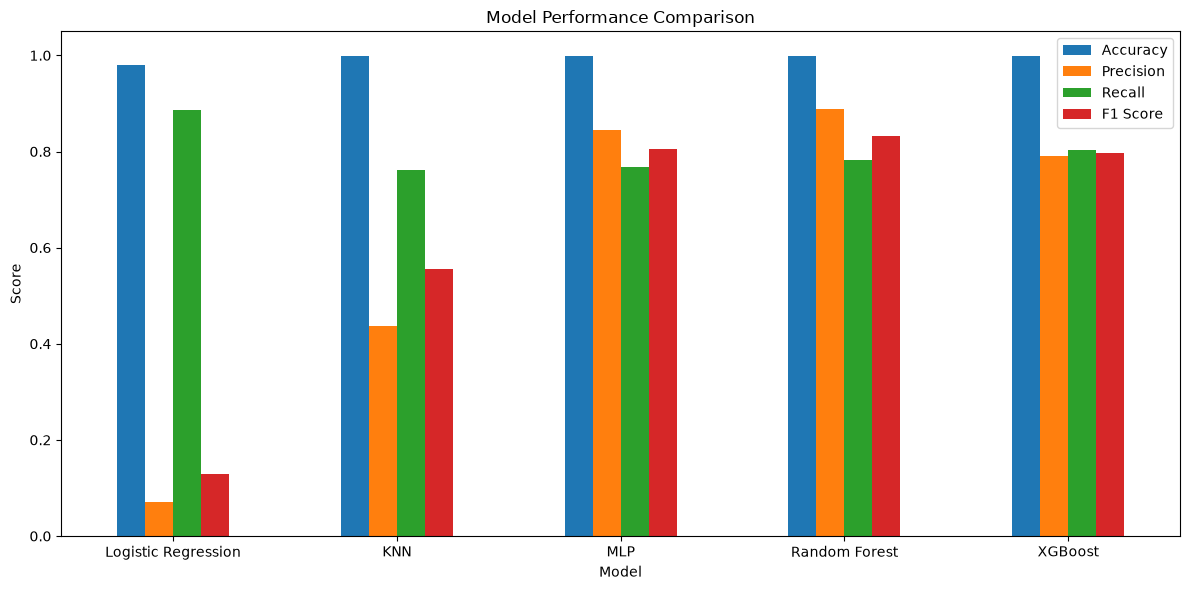

In [13]:
results[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1.05)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Confusion Matrices

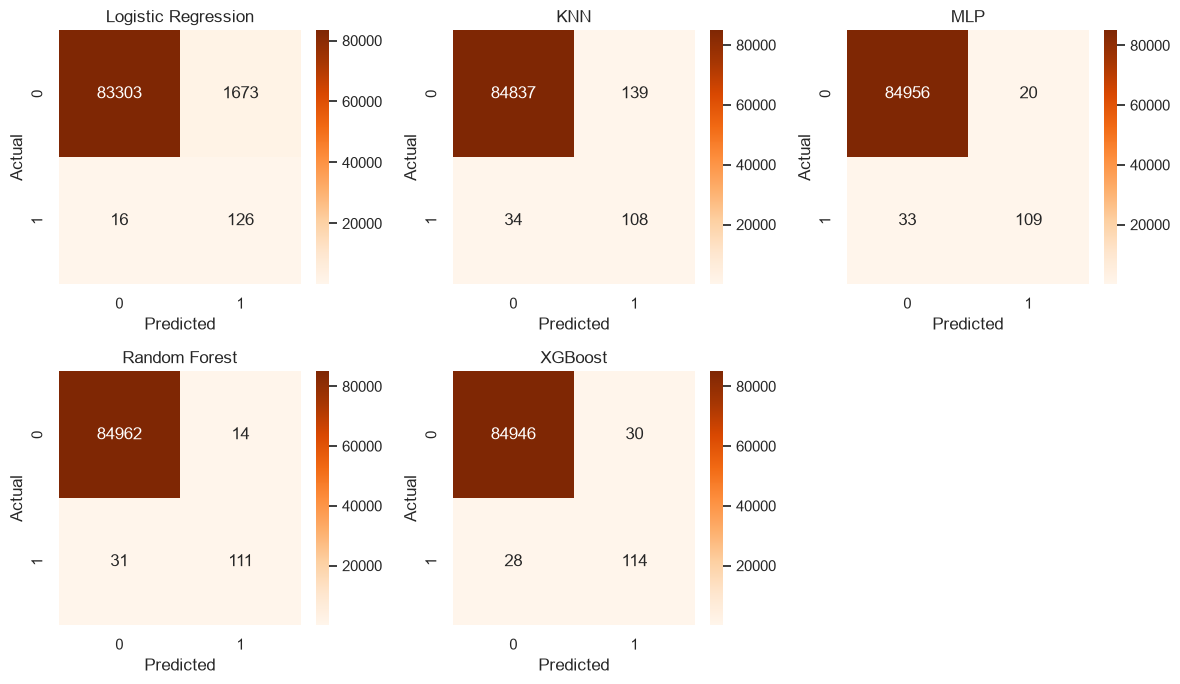

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, (name, df) in zip(axes.flat, models.items()):
    sns.heatmap(
        confusion_matrix(df["actual"], df["prediction"], labels=[0, 1]),
        annot=True, fmt="d", ax=ax, cmap="Oranges"
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

## ROC Curves

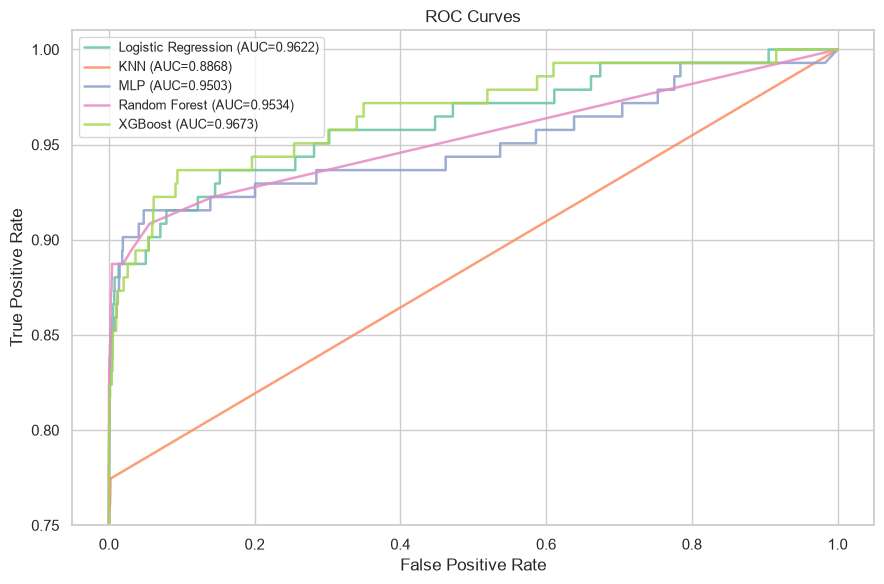

In [52]:
plt.figure(figsize=(9, 6))

for name, df in models.items():
    fpr, tpr, _ = roc_curve(df["actual"], df["probability_non_benign"])
    auc = roc_auc_score(df["actual"], df["probability_non_benign"])

    plt.plot(fpr, tpr, linewidth=1.8, alpha=0.85,
             label=f"{name} (AUC={auc:.4f})")

plt.ylim(0.75, 1.01)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

## Precision Recall Curves

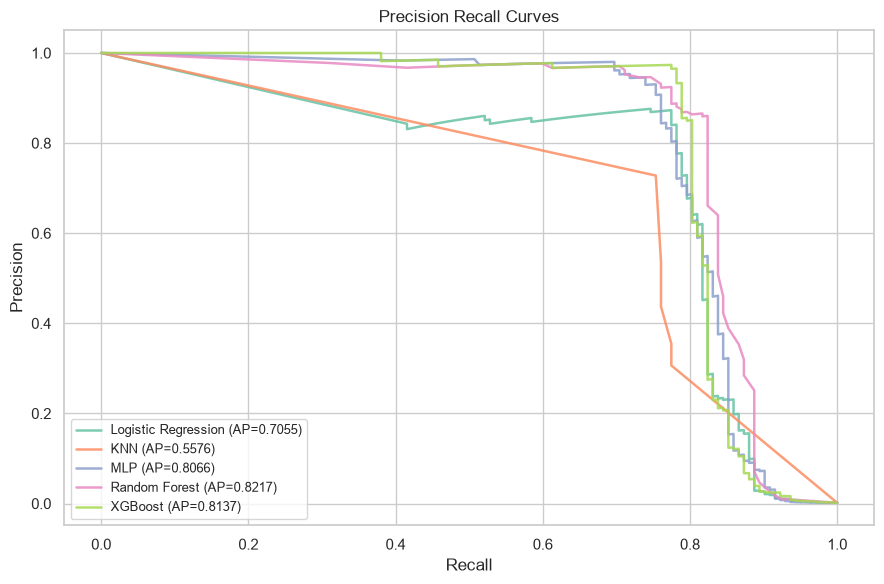

In [50]:
plt.figure(figsize=(9, 6))

for name, df in models.items():
    precision, recall, _ = precision_recall_curve(
        df["actual"], df["probability_non_benign"]
    )
    ap = average_precision_score(df["actual"], df["probability_non_benign"])

    plt.plot(recall, precision, linewidth=1.8, alpha=0.85,
             label=f"{name} (AP={ap:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision Recall Curves")
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

## Error Rate Comparisons

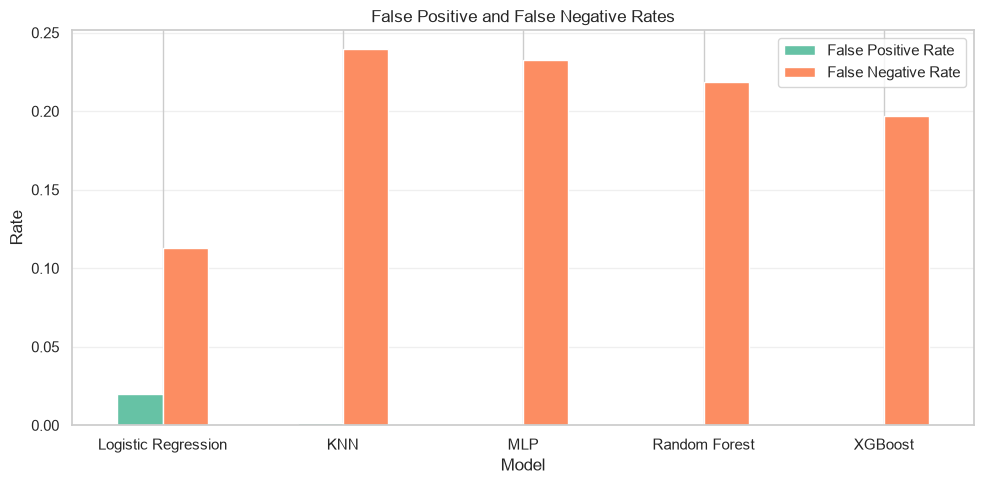

In [46]:
errors = []

for name, df in models.items():
    tn, fp, fn, tp = confusion_matrix(
        df["actual"], df["prediction"], labels=[0, 1]
    ).ravel()

    errors.append({
        "Model": name,
        "False Positive Rate": fp / (fp + tn),
        "False Negative Rate": fn / (fn + tp)
    })

errors = pd.DataFrame(errors).set_index("Model")

errors.plot(kind="bar", figsize=(10, 5))
plt.title("False Positive and False Negative Rates")
plt.ylabel("Rate")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Error Heatmap

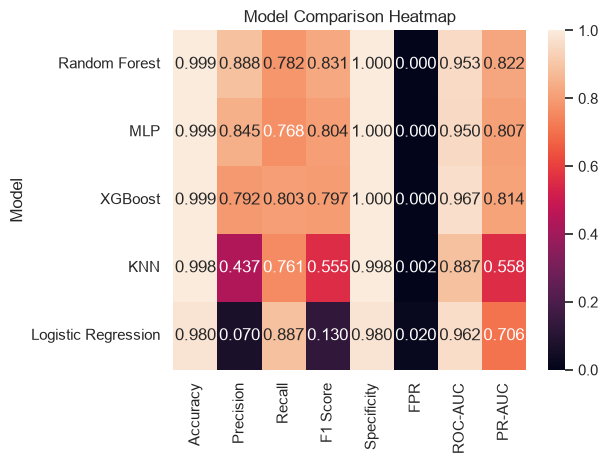

In [49]:
sns.heatmap(results, annot=True, fmt=".3f", vmin=0, vmax=1)

plt.title("Model Comparison Heatmap")
plt.tight_layout()
plt.show()

## Rank Models

In [29]:
results = results.sort_values("F1 Score", ascending=False)

display(results.round(4))

,Accuracy,Precision,Recall,F1 Score,Specificity,FPR,ROC-AUC,PR-AUC
Model,,,,,,,,
Random Forest,0.9995,0.8880,0.7817,0.8315,0.9998,0.0002,0.9534,0.8217
MLP,0.9994,0.8450,0.7676,0.8044,0.9998,0.0002,0.9503,0.8066
XGBoost,0.9993,0.7917,0.8028,0.7972,0.9996,0.0004,0.9673,0.8137
KNN,0.9980,0.4372,0.7606,0.5553,0.9984,0.0016,0.8868,0.5576
Logistic Regression,0.9802,0.0700,0.8873,0.1298,0.9803,0.0197,0.9622,0.7055
